<a href="https://colab.research.google.com/github/freyebeans/ASU-assignments/blob/main/MAT422/HW3.5-3.6/notebook.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# MAT422 Section 3.5 & 3.6 K-means and Support Vector Machines
Michael Bishop

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs, make_classification
from sklearn.cluster import KMeans
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score

np.set_printoptions(precision=4, suppress=True)

## 3.5 K-means
$k$-means clustering allows us to partion a set of $d$-dimensional real vectors $(x_1,x_2,\dots,x_n)$ into $k<n$ sets, minimizing the sum of squared distance of each vector in each set to the mean/centroid of that set.

Cluster centers:
[[-6.0862  0.29  ]
 [ 6.9694  9.6804]
 [ 4.4806 -0.2665]
 [-8.7305 -7.4205]
 [-9.4973  1.2897]]
Inertia: 258.1710894248048


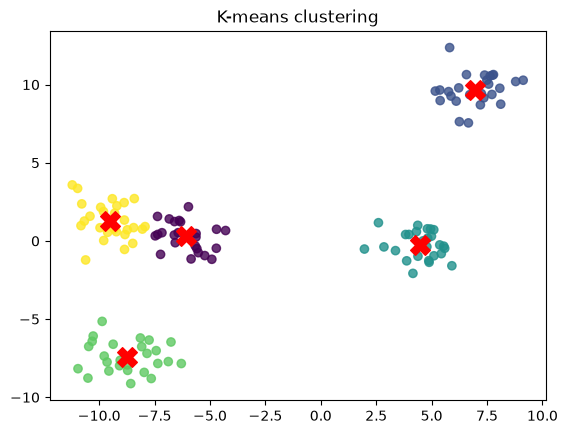

In [2]:
X, true_labels = make_blobs(n_samples=130, centers=5, cluster_std=1, random_state=248)
kmeans = KMeans(n_clusters=5, n_init=10, random_state=248)
cluster_labels = kmeans.fit_predict(X)

print("Cluster centers:")
print(kmeans.cluster_centers_)
print("Inertia:", kmeans.inertia_)

plt.scatter(X[:,0], X[:,1], c=cluster_labels, cmap="viridis", alpha=0.8)
plt.scatter(kmeans.cluster_centers_[:,0], kmeans.cluster_centers_[:,1], marker="X", s=200, color="red")
plt.title("K-means clustering")
plt.show()

Inertia is the sum of the square distances from each vector to the mean/centroid of the cluster that vector belongs to. As you can see, the inertia is quite small considering that there are 130 vectors, meaning that the k-means clustering did a good job partitioning the vectors into sets with low variance.
## 3.6 Support Vector Machines
Provided a set of examples that fall into one of two categories, we can train an SVM to assign new data points to one of the two categories. The SVM achieves this by mapping the data points to a high-dimensional space that contains a hyperplane the distinctly categorizes the data points. This mapping is done in such a may to maximize the gap between the two categories so the categorization can be done confidently.

Training accuracy: 0.9857142857142858
Number of support vectors: [5 6]


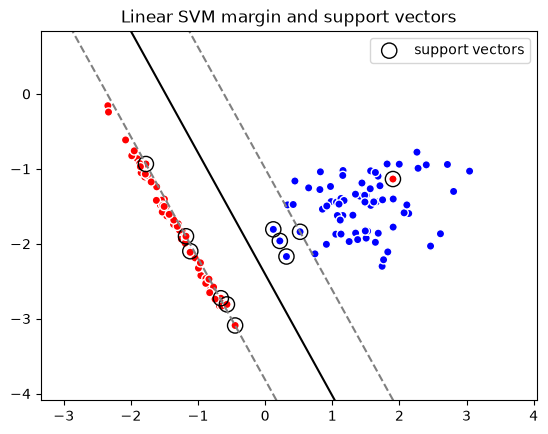

In [6]:
Xc, yc = make_classification(n_samples=140, n_features=2, n_redundant=0, n_informative=2,
                             n_clusters_per_class=1, class_sep=1.5, random_state=248)
svm = SVC(kernel="linear", C=1.0)
svm.fit(Xc, yc)
pred = svm.predict(Xc)

print("Training accuracy:", accuracy_score(yc, pred))
print("Number of support vectors:", svm.n_support_)

xx, yy = np.meshgrid(np.linspace(Xc[:,0].min()-1, Xc[:,0].max()+1, 150),
                     np.linspace(Xc[:,1].min()-1, Xc[:,1].max()+1, 150))
Z = svm.decision_function(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)

plt.contour(xx, yy, Z, levels=[-1, 0, 1], colors=["gray", "black", "gray"], linestyles=["--", "-", "--"])
plt.scatter(Xc[:,0], Xc[:,1], c=yc, cmap="bwr", edgecolor="white")
plt.scatter(svm.support_vectors_[:,0], svm.support_vectors_[:,1], s=120, facecolors="none", edgecolors="black", label="support vectors")
plt.title("Linear SVM margin and support vectors")
plt.legend()
plt.show()



As you can see above, the training accuracy of the above SVM is very high, showing that they can be used to predict the categorization of new data points.
## Reflection and Rubric Checklist
- I explained each concpet before and after the code.
- I verifed important claims numerically or visually.
- I changed and extended at least one example so that the notebook reflects my own work.
- I ran the notebook in its entirety without error.
- I saved the notebook from Google Colab directly to GitHub as per course instructions.